### Clasificación

| Tipo | Descripción | Variables del dataset|
|---|---|---|
| **Nominal** | Categorías sin orden — ninguna categoría es "mayor" que otra | Sexo de la víctima, Estado Civil, País de Nacimiento, Pertenencia Grupal, Pertenencia Étnica, Código DANE Municipio, Municipio del hecho DANE, Departamento del hecho DANE, Código DANE Departamento, Escenario del Hecho, Zona del Hecho, Actividad Durante el Hecho, Circunstancia del Hecho Detallada, Manera de muerte, Mecanismo Causal de la Lesión Fatal, Diagnóstico Topográfico de la Lesión Fatal, Presunto Agresor Detallado, Localidad del Hecho, Ancestro Racial, Pueblo Indígena, Orientación Sexual, Identidad de Género, Transgénero. |
| **Ordinal** | Categorías con orden — hay una jerarquía natural entre categorías | Grupo de edad quinquenal, Grupo Mayor Menor de Edad, Grupo de Edad judicial, Ciclo Vital, Escolaridad, Mes del hecho, Rango de Hora del Hecho X 3 Horas. |
| **Discreta** | Números enteros contables — no pueden tomar valores intermedios | Año del hecho |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# Cargar el archivo de homicidios
df = pd.read_csv("../Presuntos_Homicidios._Colombia,_2015_a_2024._Cifras_definitivas_20260916.csv", encoding="utf-8")

print("Datos cargados correctamente.")
print("Dimensiones del dataset:", df.shape)

# Mostrar los primeros registros
display(df.head())


Datos cargados correctamente.
Dimensiones del dataset: (125284, 33)


,ID,Año del hecho,Grupo de edad quinquenal,Grupo Mayor Menor de Edad,Grupo de Edad judicial,Ciclo Vital,Sexo de la victima,Estado Civil,País de Nacimiento,Escolaridad,...,Manera de muerte,Mecanismo Causal de la Lesión Fatal,Diagnostico Topográfico de la Lesión Fatal,Presunto Agresor Detallado,Localidad del Hecho,Ancestro Racial,Pueblo Indígena,Orientación Sexual,Identidad de Género,Transgénero
0,1,2015,(20 a 24),b) Mayor de Edad (>18 Años),(20 a 24),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica primaria,...,1 Presuntos Homicidios,Corto punzante,Trauma de abdomen,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
1,2,2015,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica primaria,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Trauma craneano,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
2,3,2015,(20 a 24),b) Mayor de Edad (>18 Años),(20 a 24),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica secundaria,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Trauma craneano,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
3,4,2015,(30 a 34),b) Mayor de Edad (>18 Años),(29 a 34),(29 a 59) Adultez,Mujer,Soltero(a),Colombia,Preescolar,...,1 Presuntos Homicidios,Corto punzante,Trauma de cuello,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
4,5,2015,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Preescolar,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Politraumatismo,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada


In [2]:

# Convertir a mayúsculas y eliminar espacios en columnas de texto
columnas_texto = df.select_dtypes(include=["object", "string"]).columns

df[columnas_texto] = df[columnas_texto].apply(
    lambda columna: columna.str.strip().str.upper()
)

print("¡Estandarización de texto realizada exitosamente!")


¡Estandarización de texto realizada exitosamente!


HISTOGRAMA

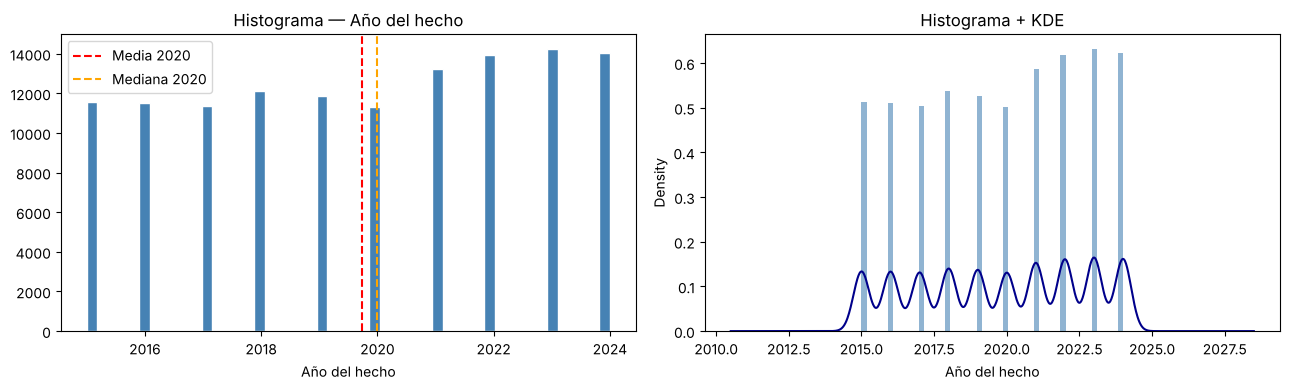

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["Año del hecho"].dropna(), bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(df["Año del hecho"].mean(),   color="red",    linestyle="--", label=f"Media {df['Año del hecho'].mean():.0f}")
axes[0].axvline(df["Año del hecho"].median(), color="orange", linestyle="--", label=f"Mediana {df['Año del hecho'].median():.0f}")
axes[0].set_title("Histograma — Año del hecho"); axes[0].set_xlabel("Año del hecho"); axes[0].legend()

df["Año del hecho"].dropna().plot.hist(bins=50, density=True, alpha=0.6, ax=axes[1], color="steelblue")
df["Año del hecho"].dropna().plot.kde(ax=axes[1], color="darkblue")
axes[1].set_title("Histograma + KDE"); axes[1].set_xlabel("Año del hecho")

plt.tight_layout(); plt.show()

 La distribución permite identificar los periodos con mayor representación de casos en el dataset. Esta información ayuda a reconocer cambios temporales y a determinar qué años requieren un análisis más detallado.

 **Insight:** Entre 2015 y 2020 los homicidios se mantuvieron estables, entre 11.300 y 12.100 por año. Desde 2021 el nivel subió a más de 13.000 y el pico fue 2023 con 14.260 casos. El problema empeoró después de la pandemia, así que el periodo 2021-2024 es el que más atención requiere.

BOXPLOT

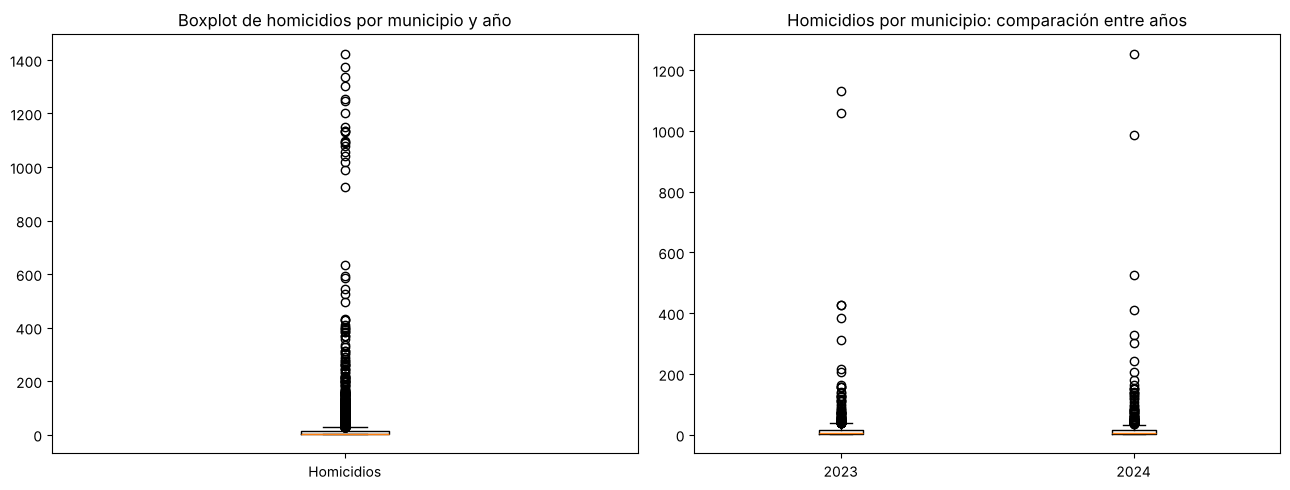

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

conteos = df.groupby(["Año del hecho", "Municipio del hecho DANE"]).size().reset_index(name="Homicidios")

axes[0].boxplot(conteos["Homicidios"].dropna())
axes[0].set_title("Boxplot de homicidios por municipio y año"); axes[0].set_xticklabels(["Homicidios"])

anios = conteos.groupby("Año del hecho")["Homicidios"].sum().nlargest(2).index.tolist()
grupos = [conteos[conteos["Año del hecho"] == anio]["Homicidios"].dropna() for anio in anios]
axes[1].boxplot(grupos, tick_labels=[str(anio) for anio in anios])
axes[1].set_title("Homicidios por municipio: comparación entre años")

plt.tight_layout(); plt.show()

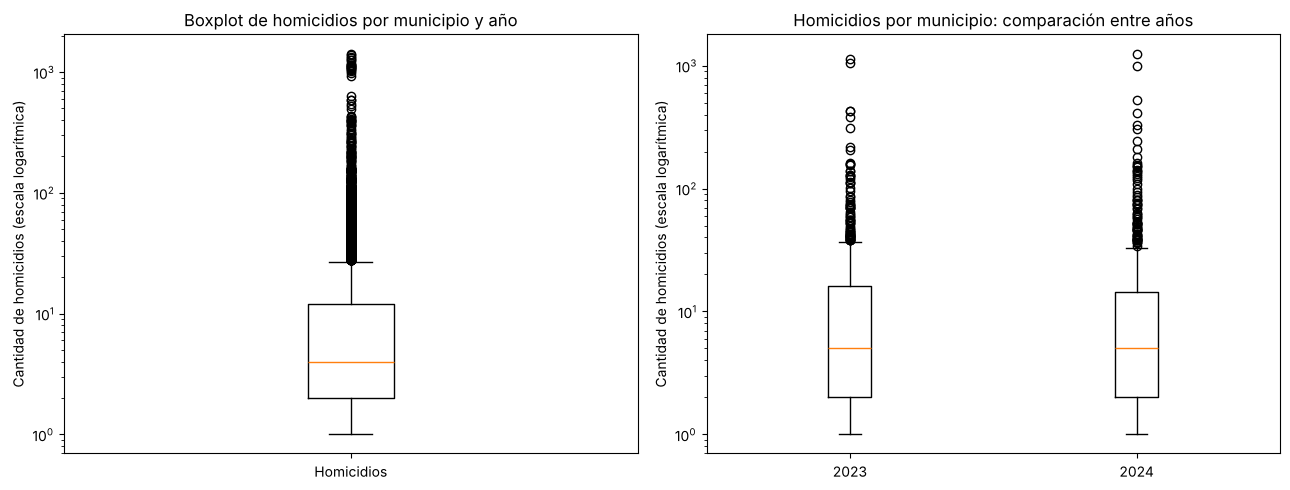

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

conteos = df.groupby(
    ["Año del hecho", "Municipio del hecho DANE"]
).size().reset_index(name="Homicidios")

axes[0].boxplot(conteos["Homicidios"].dropna())
axes[0].set_yscale("log")
axes[0].set_title("Boxplot de homicidios por municipio y año")
axes[0].set_xticklabels(["Homicidios"])
axes[0].set_ylabel("Cantidad de homicidios (escala logarítmica)")

anios = sorted(conteos["Año del hecho"].dropna().unique())[-2:]

grupos = [
    conteos[conteos["Año del hecho"] == anio]["Homicidios"].dropna()
    for anio in anios
]

axes[1].boxplot(grupos, tick_labels=[str(anio) for anio in anios])
axes[1].set_yscale("log")
axes[1].set_title("Homicidios por municipio: comparación entre años")
axes[1].set_ylabel("Cantidad de homicidios (escala logarítmica)")

plt.tight_layout()
plt.show()


El gráfico permite comparar la dispersión de los casos entre municipios y podemos detectar que hay muchos valores "atipicos". Estos valores pueden orientar una revisión territorial más detallada, aunque no necesariamente representan errores ya que debido al contexto territorial estos pueden ser valores legitimos.

**Insight:** La mitad de los municipios registra 4 homicidios o menos por año (el 72 % registra 10 o menos), pero unos pocos superan los 1.000 casos en un solo año (máximo: Santiago de Cali, 1.424 en 2015). Esos valores atípicos no son errores: son las grandes ciudades. Por eso se conservan y se usa escala logarítmica para poder compararlos.

HEATMAP (Cramér's V — variables categóricas)

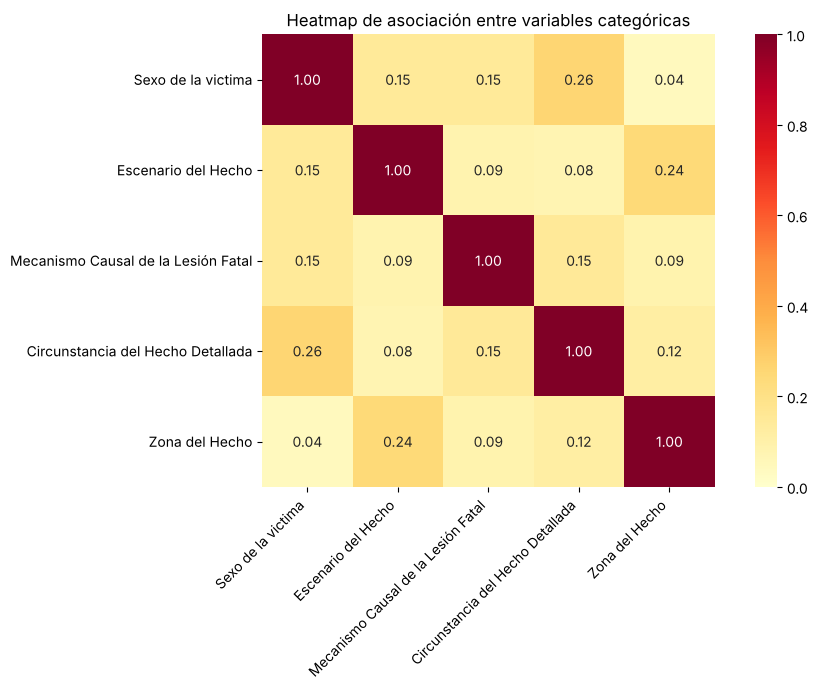

In [6]:

from scipy.stats import chi2_contingency

VARIABLES = [
    "Sexo de la victima",
    "Escenario del Hecho",
    "Mecanismo Causal de la Lesión Fatal",
    "Circunstancia del Hecho Detallada",
    "Zona del Hecho"
]

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)

    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape

    return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

matriz = pd.DataFrame(index=VARIABLES, columns=VARIABLES, dtype=float)

for var1 in VARIABLES:
    for var2 in VARIABLES:
        matriz.loc[var1, var2] = cramers_v(df[var1], df[var2])

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    square=True
)

plt.title("Heatmap de asociación entre variables categóricas")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


La matriz permite explorar qué características categóricas presentan mayor asociación. Los resultados deben interpretarse con precaución ya que descrubimos que variables como "circunstancia del hecho detallada" presenta muchos valores no resgistrados.

**Insight:** En general las asociaciones son débiles (V de Cramér < 0,3). La más alta es sexo de la víctima vs. circunstancia del hecho (0,26): las circunstancias de los homicidios de mujeres son distintas a las de los hombres. Le sigue escenario vs. zona (0,24). Como la circunstancia tiene un 64,5 % de "Sin información", este resultado se interpreta con cuidado.

TABLA PIVOTE

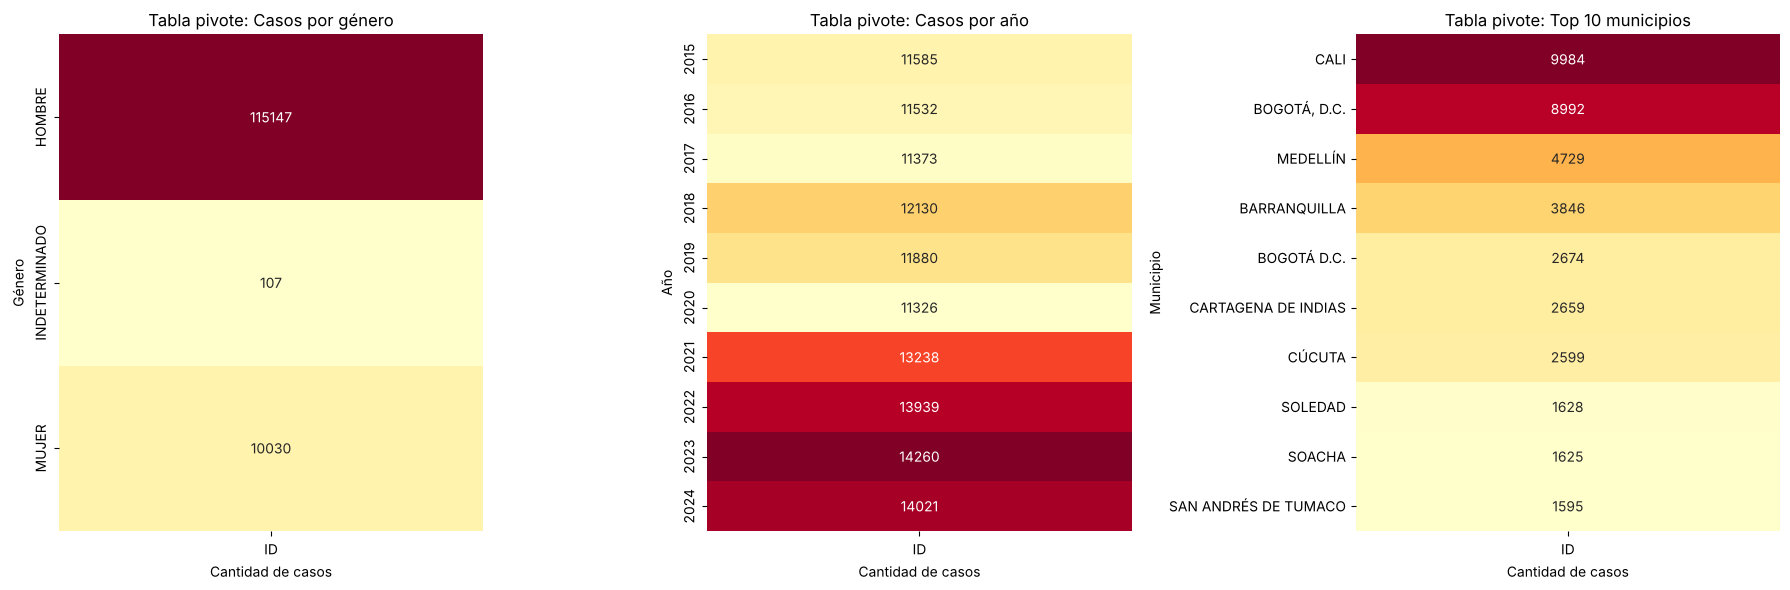

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Tabla pivote: casos por género
pivot_genero = df.pivot_table(
    values="ID",
    index="Sexo de la victima",
    aggfunc="count"
)

sns.heatmap(
    pivot_genero,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    ax=axes[0],
    cbar=False
)
axes[0].set_title("Tabla pivote: Casos por género")
axes[0].set_xlabel("Cantidad de casos")
axes[0].set_ylabel("Género")

# 2. Tabla pivote: casos por año
pivot_anio = df.pivot_table(
    values="ID",
    index="Año del hecho",
    aggfunc="count"
).sort_index()

sns.heatmap(
    pivot_anio,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    ax=axes[1],
    cbar=False
)
axes[1].set_title("Tabla pivote: Casos por año")
axes[1].set_xlabel("Cantidad de casos")
axes[1].set_ylabel("Año")

# 3. Tabla pivote: top 10 municipios
pivot_municipio = df.pivot_table(
    values="ID",
    index="Municipio del hecho DANE",
    aggfunc="count"
).sort_values(
    by="ID",
    ascending=False
).head(10)

sns.heatmap(
    pivot_municipio,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    ax=axes[2],
    cbar=False
)
axes[2].set_title("Tabla pivote: Top 10 municipios")
axes[2].set_xlabel("Cantidad de casos")
axes[2].set_ylabel("Municipio")

plt.tight_layout()
plt.show()

**Insight:** Las tablas pivote confirman los focos del problema: los hombres son 115.147 de las 125.284 víctimas, los casos anuales pasaron de 11.585 en 2015 a 14.021 en 2024 (+21 %) y Cali es el municipio con más registros. La prevención debe priorizar a los hombres en las grandes ciudades.

GRAFICOS DE BARRAS

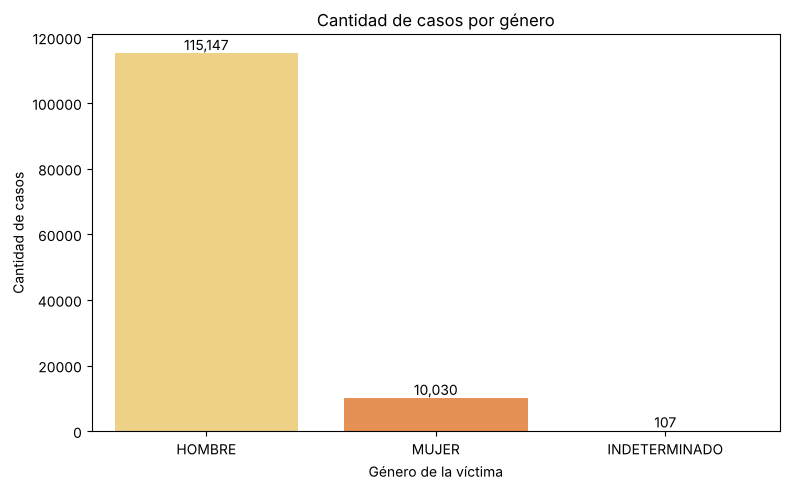

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

conteo_genero = df["Sexo de la victima"].value_counts()

sns.barplot(
    x=conteo_genero.index,
    y=conteo_genero.values,
    hue=conteo_genero.index,
    palette="YlOrRd",
    legend=False,
    ax=ax
)

ax.set_title("Cantidad de casos por género")
ax.set_xlabel("Género de la víctima")
ax.set_ylabel("Cantidad de casos")

for i, valor in enumerate(conteo_genero.values):
    ax.text(i, valor, f"{valor:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

El gráfico muestra cómo se distribuyen los registros según el sexo de la víctima. Esta comparación permite identificar diferencias en el número de casos registrados y como podemos ver gran parte de estos suceden a los hombres.

**Insight:** El 91,9 % de las víctimas son hombres (115.147) y el 8,0 % mujeres (10.030). El homicidio en Colombia es un fenómeno mayoritariamente masculino, pero los casos de mujeres merecen un análisis aparte porque ocurren en escenarios y con mecanismos distintos (ver gráfico de violín).

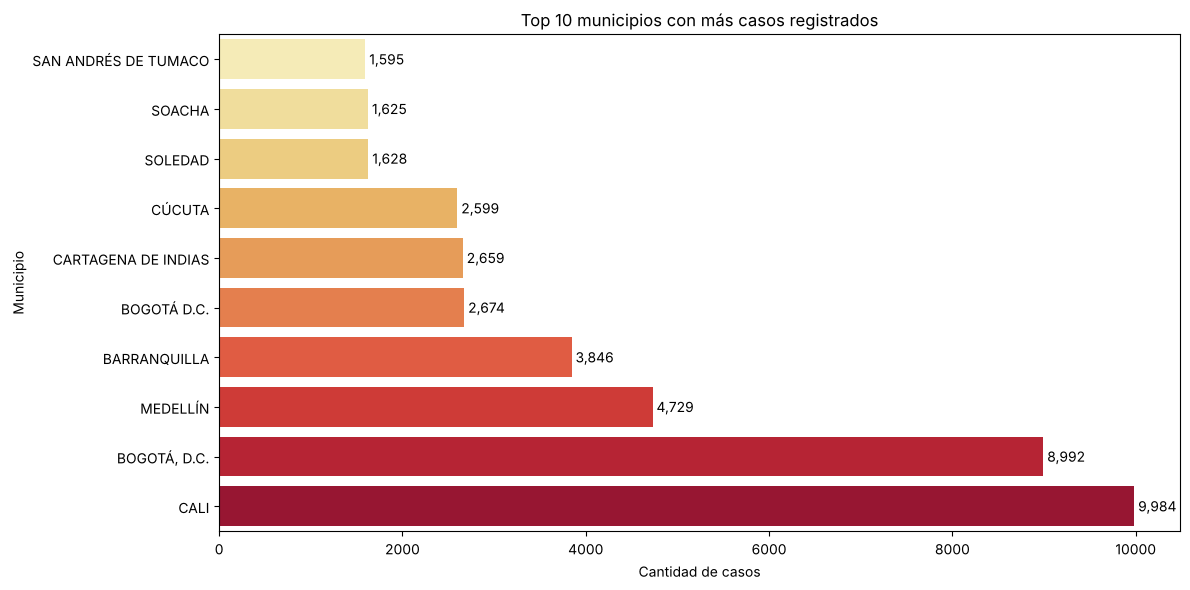

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

conteo_municipio = (
    df["Municipio del hecho DANE"]
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

sns.barplot(
    x=conteo_municipio.values,
    y=conteo_municipio.index,
    hue=conteo_municipio.index,
    palette="YlOrRd",
    legend=False,
    ax=ax
)

ax.set_title("Top 10 municipios con más casos registrados")
ax.set_xlabel("Cantidad de casos")
ax.set_ylabel("Municipio")

for i, valor in enumerate(conteo_municipio.values):
    ax.text(valor, i, f" {valor:,.0f}", va="center")

plt.tight_layout()
plt.show()

El gráfico identifica los diez municipios con mayor número de registros en el dataset. Esta información puede ayudar a priorizar análisis territoriales.

**Insight:** Cali (9.984), Bogotá (8.992) y Medellín (4.729) encabezan la lista, y los 10 municipios suman el 32 % de los casos del país. Ojo: Cali y Bogotá también aparecen con otro nombre ("SANTIAGO DE CALI", "BOGOTÁ D.C."), así que sus totales reales son mayores. Esta inconsistencia se corrige en la Fase B.

---
## Complementos de la Fase A
El dataset casi no tiene columnas numéricas (solo año, ID y códigos). Para hacer histogramas, boxplots y correlaciones de **Pearson y Spearman** se crean variables numéricas a partir de las categorías:
- **edad_aprox:** punto medio del grupo de edad quinquenal (ej. "(20 A 24)" → 22).
- **hora_aprox:** punto medio de la franja de 3 horas (ej. "(18:00 A 20:59)" → 19,5).
- **dia_num / mes_num:** día de la semana (1 = lunes) y mes (1 = enero).
- **Tabla por municipio:** total de homicidios y % con arma de fuego, % mujeres, % rural y % en fin de semana.

In [10]:
# Crear variables numéricas a partir de las categorías
# El dataset casi no trae columnas numéricas, así que las construimos

df_num = df.copy()

def punto_medio_edad(texto):
    """Convierte '(20 A 24)' en 22. Devuelve NaN si no hay edad."""
    if texto == "(80 Y MÁS)":
        return 82
    if isinstance(texto, str) and " A " in texto:
        partes = texto.strip("()").split(" A ")
        return (int(partes[0]) + int(partes[1])) / 2
    return np.nan

def hora_media(texto):
    """Convierte '(18:00 A 20:59)' en 19.5. Devuelve NaN si no hay hora."""
    if isinstance(texto, str) and ":" in texto:
        hora_inicio = int(texto.strip("()")[:2])
        return hora_inicio + 1.5
    return np.nan

# Aplicar las funciones a cada registro
df_num["edad_aprox"] = df_num["Grupo de edad quinquenal"].apply(punto_medio_edad)
df_num["hora_aprox"] = df_num["Rango de Hora del Hecho X 3 Horas"].apply(hora_media)

# Día y mes como número (1 = lunes / 1 = enero)
dias = {"LUNES": 1, "MARTES": 2, "MIÉRCOLES": 3, "JUEVES": 4, "VIERNES": 5, "SÁBADO": 6, "DOMINGO": 7}
meses = {"ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6, "JULIO": 7,
         "AGOSTO": 8, "SEPTIEMBRE": 9, "OCTUBRE": 10, "NOVIEMBRE": 11, "DICIEMBRE": 12}
df_num["dia_num"] = df_num["Dia del hecho"].map(dias)
df_num["mes_num"] = df_num["Mes del hecho"].map(meses)

print(df_num[["edad_aprox", "hora_aprox", "dia_num", "mes_num"]].describe().round(2))
print("\nRegistros sin hora informada:", df_num["hora_aprox"].isna().sum())

       edad_aprox  hora_aprox   dia_num    mes_num
count   125259.00    51302.00  125050.0  125050.00
mean        32.65       14.25       4.3       6.60
std         12.98        7.17       2.1       3.47
min          2.00        1.50       1.0       1.00
25%         22.00        7.50       2.0       4.00
50%         32.00       16.50       5.0       7.00
75%         37.00       19.50       6.0      10.00
max         82.00       22.50       7.0      12.00

Registros sin hora informada: 73982


In [11]:
# Tabla resumen por municipio (una fila = un municipio)
# Se excluye el código 999, que corresponde a municipio sin información

df_mun = df_num[df_num["Código Dane Municipio"] != 999].copy()
df_mun["es_arma_fuego"] = (df_mun["Mecanismo Causal de la Lesión Fatal"] == "PROYECTIL DE ARMA DE FUEGO").astype(int)
df_mun["es_mujer"] = (df_mun["Sexo de la victima"] == "MUJER").astype(int)
df_mun["es_rural"] = (df_mun["Zona del Hecho"] == "PARTE RURAL (VEREDA Y CAMPO)").astype(int)
df_mun["es_fin_semana"] = df_mun["dia_num"].isin([6, 7]).astype(int)

# Agrupar: total de casos y porcentajes por municipio
df_municipios = df_mun.groupby("Código Dane Municipio").agg(
    homicidios=("ID", "count"),
    edad_promedio=("edad_aprox", "mean"),
    pct_arma_fuego=("es_arma_fuego", "mean"),
    pct_mujeres=("es_mujer", "mean"),
    pct_rural=("es_rural", "mean"),
    pct_fin_semana=("es_fin_semana", "mean"),
).reset_index()

# Pasar proporciones a porcentaje
for columna in ["pct_arma_fuego", "pct_mujeres", "pct_rural", "pct_fin_semana"]:
    df_municipios[columna] = (df_municipios[columna] * 100).round(1)

print("Municipios:", len(df_municipios))
df_municipios.describe().round(2)

Municipios: 1085


,Código Dane Municipio,homicidios,edad_promedio,pct_arma_fuego,pct_mujeres,pct_rural,pct_fin_semana
count,1085.00,1085.00,1085.00,1085.00,1085.00,1085.0,1085.00
mean,38450.03,115.38,36.47,64.04,10.64,52.7,40.51
std,26263.25,567.03,7.24,26.43,14.03,28.1,21.02
min,5001.00,1.00,14.00,0.00,0.00,0.0,0.00
25%,15690.00,7.00,32.22,50.00,2.80,33.3,30.60
50%,25845.00,23.00,34.94,71.10,7.70,54.1,37.50
75%,66088.00,74.00,39.14,82.90,12.50,73.1,50.00
max,99773.00,11667.00,82.00,100.00,100.00,100.0,100.00


### Histogramas de las variables numéricas

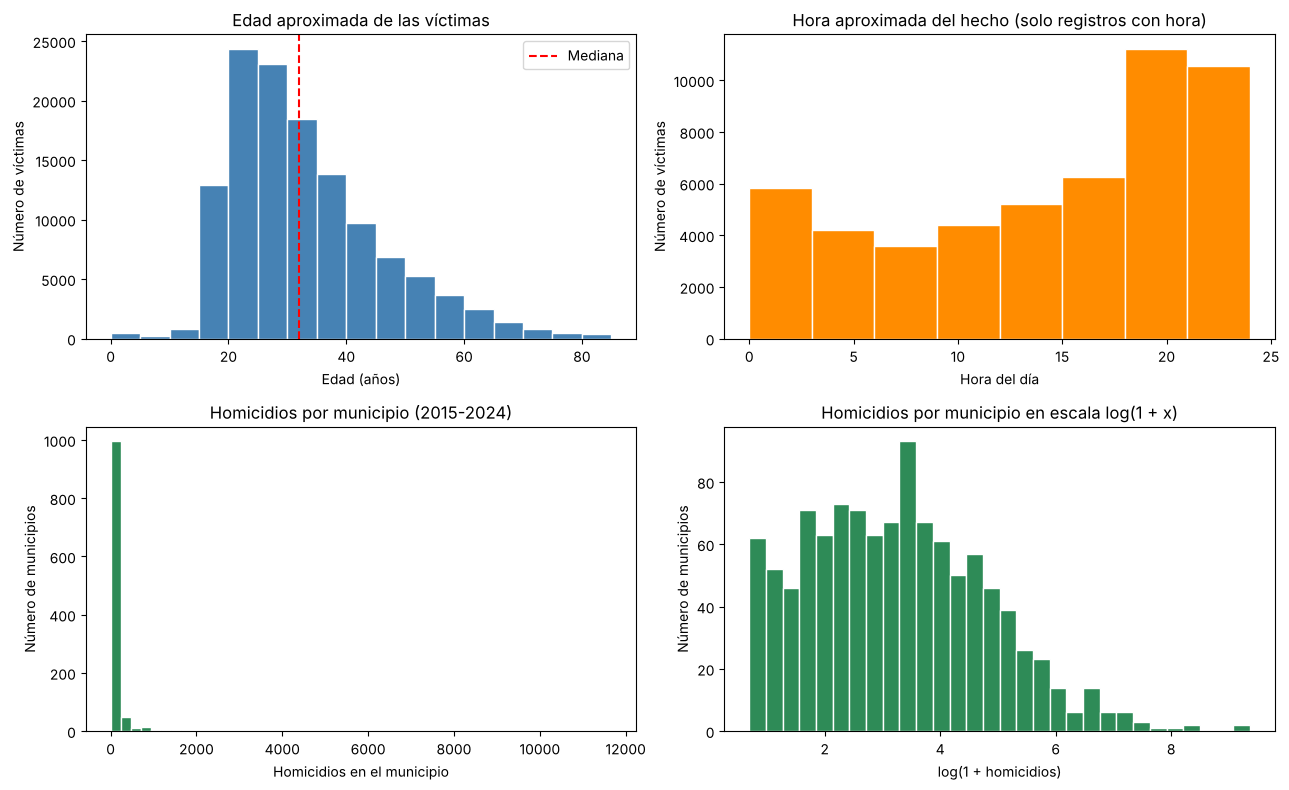

In [12]:
# Histogramas de las variables numéricas
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].hist(df_num["edad_aprox"].dropna(), bins=range(0, 90, 5), color="steelblue", edgecolor="white")
axes[0, 0].axvline(df_num["edad_aprox"].median(), color="red", linestyle="--", label="Mediana")
axes[0, 0].set_title("Edad aproximada de las víctimas")
axes[0, 0].set_xlabel("Edad (años)")
axes[0, 0].set_ylabel("Número de víctimas")
axes[0, 0].legend()

axes[0, 1].hist(df_num["hora_aprox"].dropna(), bins=range(0, 25, 3), color="darkorange", edgecolor="white")
axes[0, 1].set_title("Hora aproximada del hecho (solo registros con hora)")
axes[0, 1].set_xlabel("Hora del día")
axes[0, 1].set_ylabel("Número de víctimas")

# Gráficos de abajo: homicidios por municipio (normal y en escala log)
axes[1, 0].hist(df_municipios["homicidios"], bins=50, color="seagreen", edgecolor="white")
axes[1, 0].set_title("Homicidios por municipio (2015-2024)")
axes[1, 0].set_xlabel("Homicidios en el municipio")
axes[1, 0].set_ylabel("Número de municipios")

axes[1, 1].hist(np.log1p(df_municipios["homicidios"]), bins=30, color="seagreen", edgecolor="white")
axes[1, 1].set_title("Homicidios por municipio en escala log(1 + x)")
axes[1, 1].set_xlabel("log(1 + homicidios)")
axes[1, 1].set_ylabel("Número de municipios")

plt.tight_layout()
plt.savefig("figuras/histogramas.png", dpi=150)
plt.show()

**Insight:** La edad tiene sesgo a la derecha: la mediana es 32 años y el 58,6 % de las víctimas tiene entre 18 y 34 años, así que la prevención debe enfocarse en adultos jóvenes. El 42 % de los casos con hora informada ocurre entre las 18:00 y las 23:59, aunque el 59 % de los registros no tiene hora. Los homicidios por municipio están muy sesgados (asimetría 16,2) y con log(1 + x) quedan casi simétricos (0,46), por eso en la Fase B se aplica esa transformación.

### Boxplots por municipio (detección de outliers)

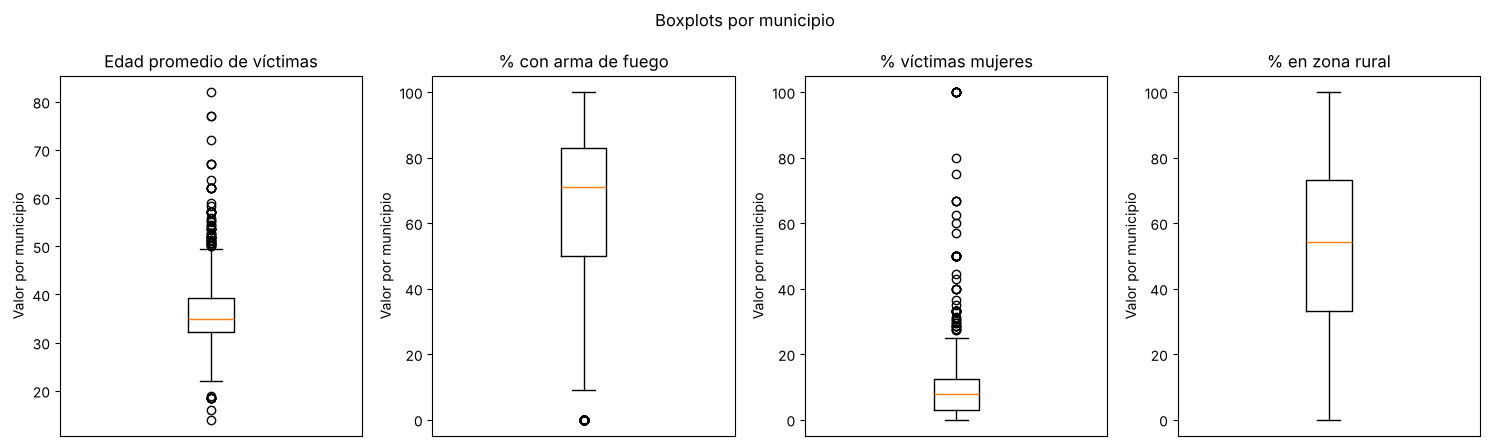

In [13]:
# Boxplots para detectar outliers en las variables de municipio
columnas_box = ["edad_promedio", "pct_arma_fuego", "pct_mujeres", "pct_rural"]
titulos_box = ["Edad promedio de víctimas", "% con arma de fuego", "% víctimas mujeres", "% en zona rural"]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for i in range(4):
    axes[i].boxplot(df_municipios[columnas_box[i]].dropna())
    axes[i].set_title(titulos_box[i])
    axes[i].set_xticks([])
    axes[i].set_ylabel("Valor por municipio")

plt.suptitle("Boxplots por municipio")
plt.tight_layout()
plt.savefig("figuras/boxplots_municipio.png", dpi=150)
plt.show()

**Insight:** El % con arma de fuego (mediana 71,1 %) y el % de mujeres (mediana 7,7 %) tienen 82 municipios atípicos cada uno. Casi todos son municipios con muy pocos casos (mediana de 2 a 4 homicidios en 10 años), donde un solo hecho cambia mucho el porcentaje. El % rural no tiene atípicos. Se conservan porque son datos reales, no errores.

### Heatmap de correlación — Pearson y Spearman (nivel municipio)

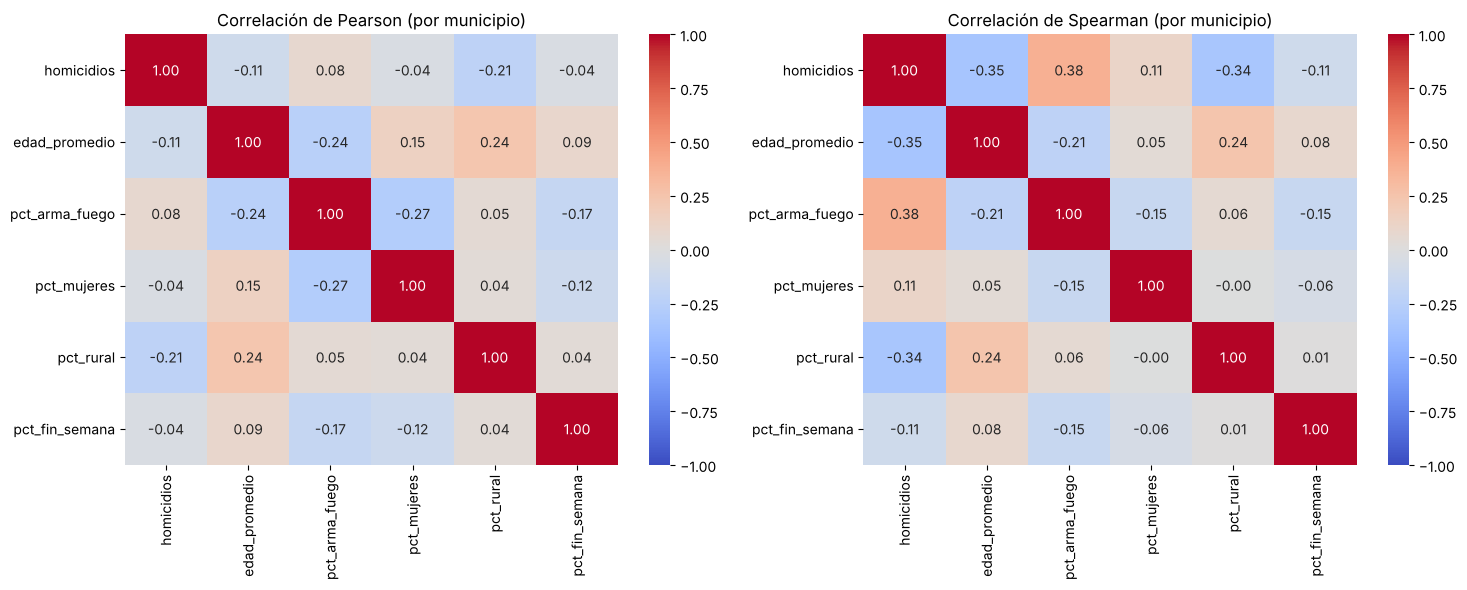

In [14]:
# Correlación de Pearson (lineal) y Spearman (por rangos)
columnas_corr = ["homicidios", "edad_promedio", "pct_arma_fuego", "pct_mujeres", "pct_rural", "pct_fin_semana"]
corr_pearson = df_municipios[columnas_corr].corr(method="pearson")
corr_spearman = df_municipios[columnas_corr].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlación de Pearson (por municipio)")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlación de Spearman (por municipio)")

plt.tight_layout()
plt.savefig("figuras/correlacion_pearson_spearman.png", dpi=150)
plt.show()

**Insight:** Spearman muestra relaciones más claras que Pearson porque Pearson se distorsiona con los valores extremos (Cali, Bogotá). Los municipios con más homicidios tienen más uso de arma de fuego (ρ = 0,38), víctimas más jóvenes (ρ = −0,35) y menos casos rurales (ρ = −0,34). La violencia masiva es urbana, con arma de fuego y contra jóvenes.

### Heatmap de correlación — Pearson y Spearman (nivel víctima)

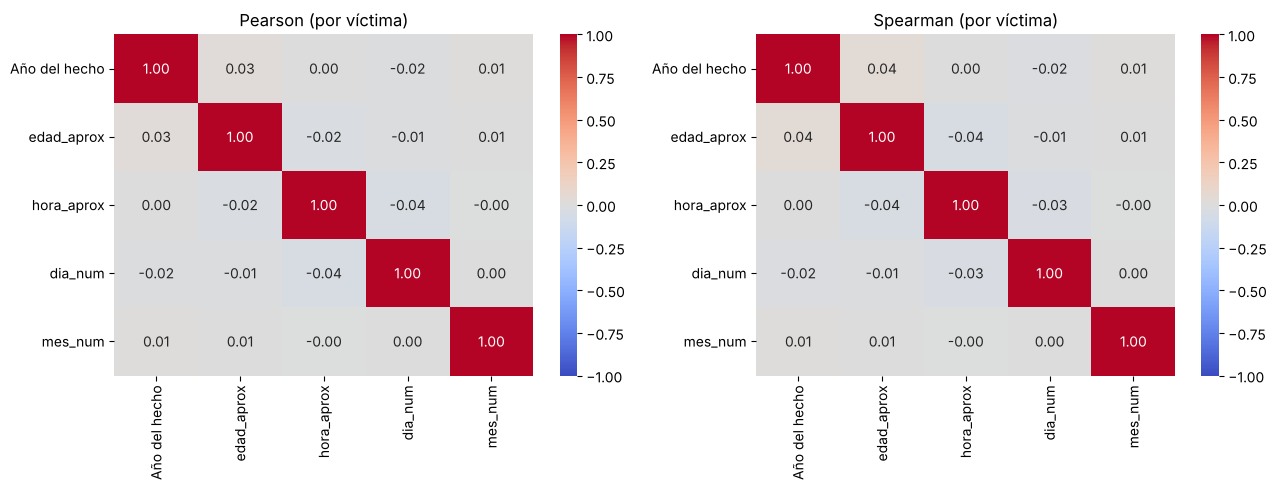

In [15]:
# Misma comparación a nivel de víctima (cada fila = una víctima)
columnas_victima = ["Año del hecho", "edad_aprox", "hora_aprox", "dia_num", "mes_num"]
corr_victima_p = df_num[columnas_victima].corr(method="pearson")
corr_victima_s = df_num[columnas_victima].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(corr_victima_p, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson (por víctima)")
sns.heatmap(corr_victima_s, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman (por víctima)")

plt.tight_layout()
plt.savefig("figuras/correlacion_victima.png", dpi=150)
plt.show()

**Insight:** A nivel de víctima todas las correlaciones son casi cero (|r| ≤ 0,04): la edad, la hora, el día y el mes no varían juntos de forma lineal. Los patrones del dataset están en las variables categóricas (sexo, mecanismo, escenario), por eso los modelos de la Fase C las usarán codificadas.

### Gráfico adicional 1 — Violín: edad según mecanismo causal y sexo

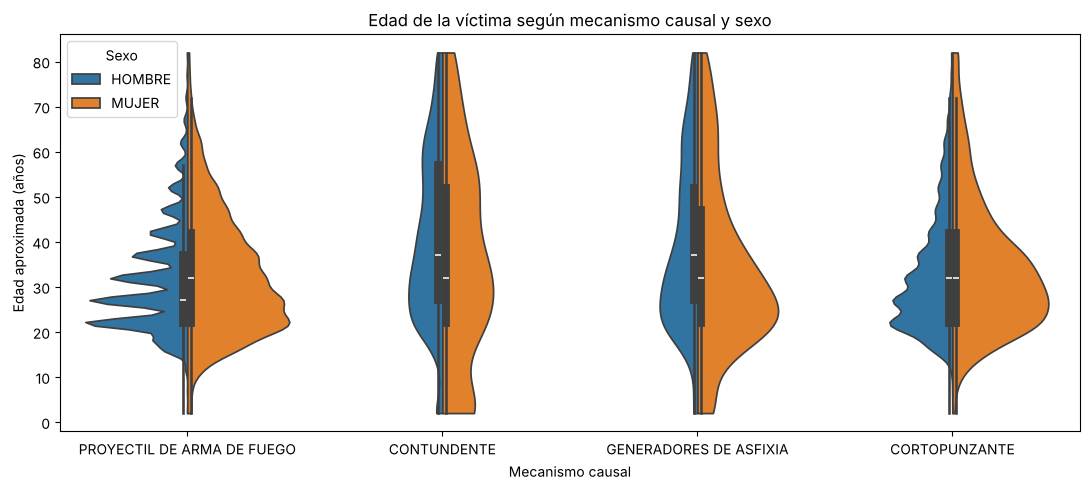

In [16]:
# Gráfico adicional — violín de edad según mecanismo causal
principales = ["PROYECTIL DE ARMA DE FUEGO", "CORTOPUNZANTE", "CONTUNDENTE", "GENERADORES DE ASFIXIA"]
df_violin = df_num[df_num["Mecanismo Causal de la Lesión Fatal"].isin(principales)]

fig, ax = plt.subplots(figsize=(11, 5))
sns.violinplot(data=df_violin, x="Mecanismo Causal de la Lesión Fatal", y="edad_aprox",
               hue="Sexo de la victima", hue_order=["HOMBRE", "MUJER"], split=True, cut=0, ax=ax)
ax.set_title("Edad de la víctima según mecanismo causal y sexo")
ax.set_xlabel("Mecanismo causal")
ax.set_ylabel("Edad aproximada (años)")
ax.legend(title="Sexo")

plt.tight_layout()
plt.savefig("figuras/violin_edad_mecanismo.png", dpi=150)
plt.show()

**Insight:** Los hombres asesinados con arma de fuego son las víctimas más jóvenes (mediana 27 años), mientras que en los hombres muertos por objeto contundente o asfixia la mediana sube a 37 años. En las mujeres la mediana es 32 años en los cuatro mecanismos. El arma de fuego es el mecanismo típico de la violencia contra hombres jóvenes.


### Gráfico adicional 2 — Pareto de departamentos

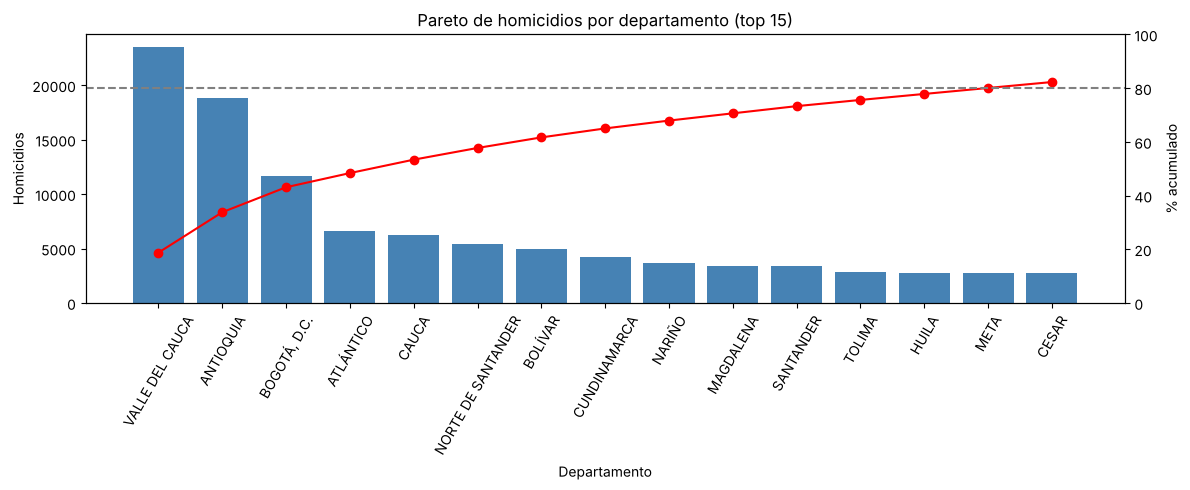

          departamento  homicidios  pct_acumulado
0      VALLE DEL CAUCA       23491           18.8
1            ANTIOQUIA       18852           33.8
2         BOGOTÁ, D.C.       11666           43.1
3            ATLÁNTICO        6608           48.4
4                CAUCA        6258           53.4
5   NORTE DE SANTANDER        5461           57.7
6              BOLÍVAR        4930           61.7
7         CUNDINAMARCA        4186           65.0
8               NARIÑO        3660           67.9
9            MAGDALENA        3382           70.6
10           SANTANDER        3357           73.3
11              TOLIMA        2893           75.6
12               HUILA        2801           77.9
13                META        2789           80.1
14               CESAR        2761           82.3


In [17]:
# Gráfico adicional — pareto de departamentos
df_pareto = df["Departamento del hecho DANE"].replace({"BOGOTÁ D.C.": "BOGOTÁ, D.C.", "QUINDIO": "QUINDÍO"})
df_pareto = df_pareto.value_counts().reset_index()
df_pareto.columns = ["departamento", "homicidios"]
df_pareto["pct_acumulado"] = df_pareto["homicidios"].cumsum() / df_pareto["homicidios"].sum() * 100
top15 = df_pareto.head(15)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(top15["departamento"], top15["homicidios"], color="steelblue")
ax.set_title("Pareto de homicidios por departamento (top 15)")
ax.set_xlabel("Departamento")
ax.set_ylabel("Homicidios")
ax.tick_params(axis="x", rotation=60)

# Segundo eje con el porcentaje acumulado
ax2 = ax.twinx()
ax2.plot(top15["departamento"], top15["pct_acumulado"], color="red", marker="o")
ax2.axhline(80, color="gray", linestyle="--")
ax2.set_ylabel("% acumulado")
ax2.set_ylim(0, 100)

plt.tight_layout()
plt.savefig("figuras/pareto_departamentos.png", dpi=150)
plt.show()
print(top15[["departamento", "homicidios", "pct_acumulado"]].round(1))

**Insight:** Valle del Cauca, Antioquia y Bogotá suman el 43,1 % de los homicidios del país, y se necesitan 14 de los 33 departamentos para llegar al 80 %. Enfocar la prevención en los 3 primeros cubre casi la mitad del problema.